In [1]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import joblib
import time

sys.path.insert(0, '../..') # Load Parent directory to import utils
from utils.plotting import plot_movement_data
from utils.plotting import plot_movement_data_3d
from utils.constants import Configs
from utils.helper_functions import load_outlier_data

SMART_RETAIL_OUTLIERS_LEFT_PATH: /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_left.csv
SMART_RETAIL_OUTLIERS_RIGHT_PATH: /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_right.csv


/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/.venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


In [2]:
# Load the processed data from the csv
cache_path = Configs.SMART_RETAIL_FILTERED_DATA_BIMANUAL
if os.path.exists(cache_path):
    print(f"Loading processed data from {cache_path}")
    df = pd.read_csv(cache_path)
else:
    print(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

Loading processed data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/data/processed/filtered_data_bimanual.csv


In [3]:
print("\n--- Fusing Outliers into a singular Ground Truth ---")

# Load the known outliers from the csv
outliers_left_csv, total_known_outliers_left = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_LEFT_PATH)
outliers_right_csv, total_known_outliers_right = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_RIGHT_PATH)


outliers_bimanual = pd.concat([outliers_left_csv, outliers_right_csv])
total_known_outliers = len(outliers_bimanual)

# O drop_duplicates garante que se o sub 13 falhou com as duas mãos, conta como 1 erro
outliers_bimanual = outliers_bimanual.drop_duplicates(subset=['sub', 'repID']).copy()
total_known_outliers = len(outliers_bimanual)

print(f"Total de OUTLIERS BIMANUAIS (Ground Truth): {total_known_outliers}")


--- Fusing Outliers into a singular Ground Truth ---
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_left.csv
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_right.csv
Total de OUTLIERS BIMANUAIS (Ground Truth): 24


In [4]:
# Discard from dataset
df.drop(df[df['sub']== 13].index, inplace=True)

# Discard from outliers csv
outliers_bimanual.drop(outliers_bimanual[outliers_bimanual['sub'] == 13].index, inplace=True)
outliers_bimanual[outliers_bimanual['sub'] == 13]

,sub,repID


In [5]:
# LOAD INLIERS

target_movements = ['Pick', 'Place', 'Park']

inliers_dict = {}
for mov in target_movements:
    csv_path = Configs.movement_inliers_umap_path(mov)
    
    if os.path.exists(csv_path):
        print(f"Loading DTW inliers for {mov} from {csv_path}")
        inliers_dict[mov] = pd.read_csv(csv_path)
    else:
        print(f"⚠️ Aviso: Ficheiro não encontrado para {mov} em {csv_path}. Verifica se já o geraste!")

# Separar em 3 DataFrames independentes (usando .get() para não dar erro se faltar algum)
df_inliers_pick = inliers_dict.get('Pick')
df_inliers_place = inliers_dict.get('Place')
df_inliers_park = inliers_dict.get('Park')

print("\n--- Resumo dos Dados Carregados ---")
if df_inliers_pick is not None: print(f"Linhas em Pick: {len(df_inliers_pick)}")
if df_inliers_place is not None: print(f"Linhas em Place: {len(df_inliers_place)}")
if df_inliers_park is not None: print(f"Linhas em Park: {len(df_inliers_park)}")

Loading DTW inliers for Pick from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/SmartRetail_UMAP/data/processed/df_cleaned_inliers_Pick_only.csv
Loading DTW inliers for Place from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/SmartRetail_UMAP/data/processed/df_cleaned_inliers_Place_only.csv
Loading DTW inliers for Park from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/SmartRetail_UMAP/data/processed/df_cleaned_inliers_Park_only.csv

--- Resumo dos Dados Carregados ---
Linhas em Pick: 36719
Linhas em Place: 40772
Linhas em Park: 11349


--- Configuração do Gráfico para Place ---
Linhas de Inliers (Trajetórias Normais): 40772
Linhas de Outliers Detetados (Vão aparecer a Vermelho): 12443

--- A gerar gráfico 3D para a Mão ESQUERDA ---


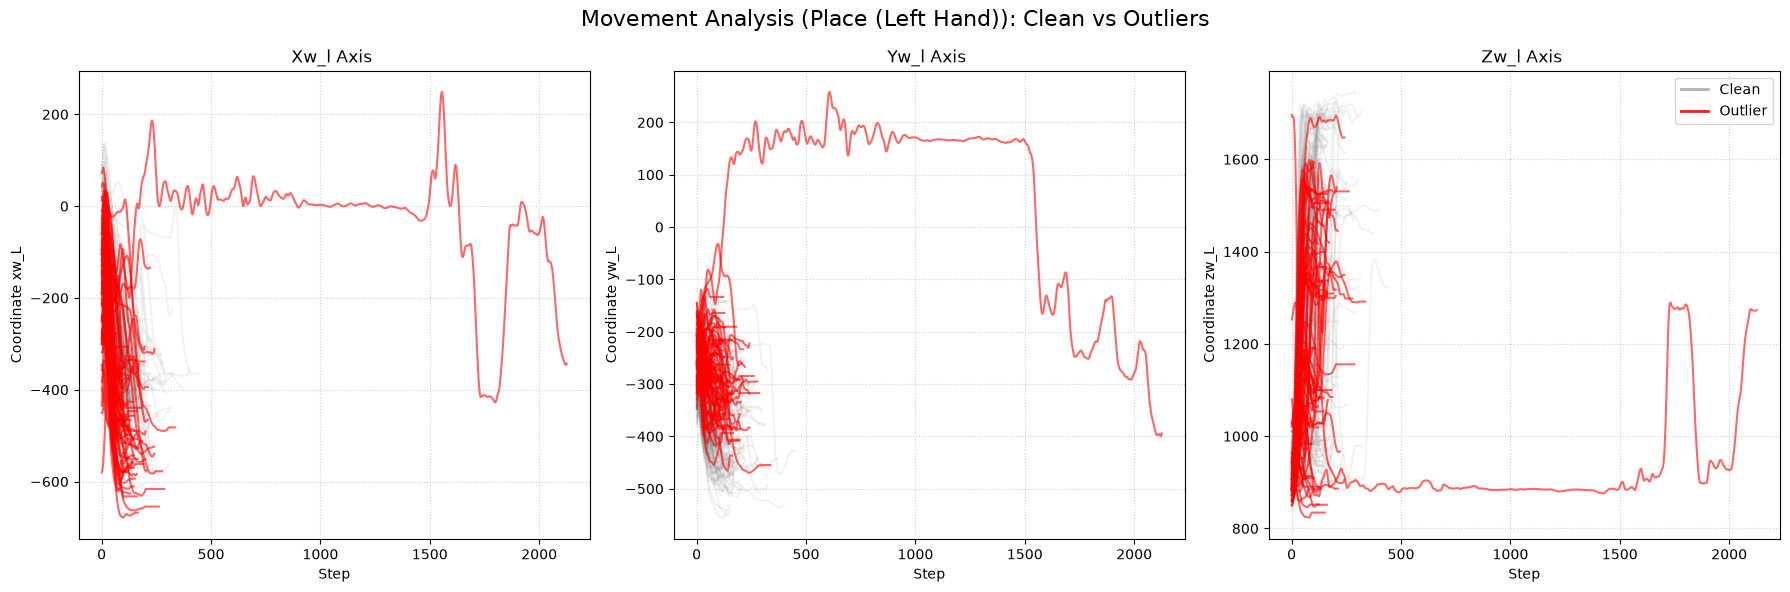


--- A gerar gráfico 3D para a Mão DIREITA ---


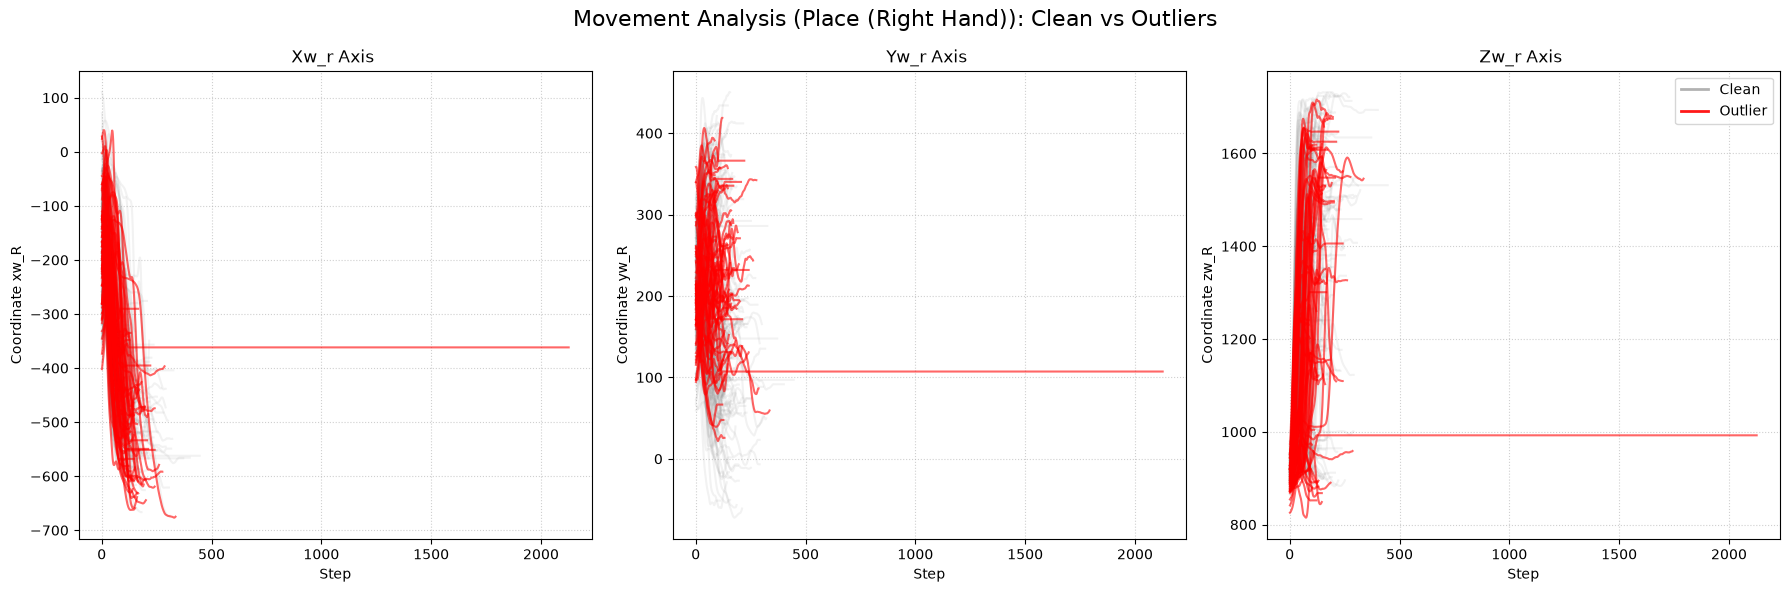

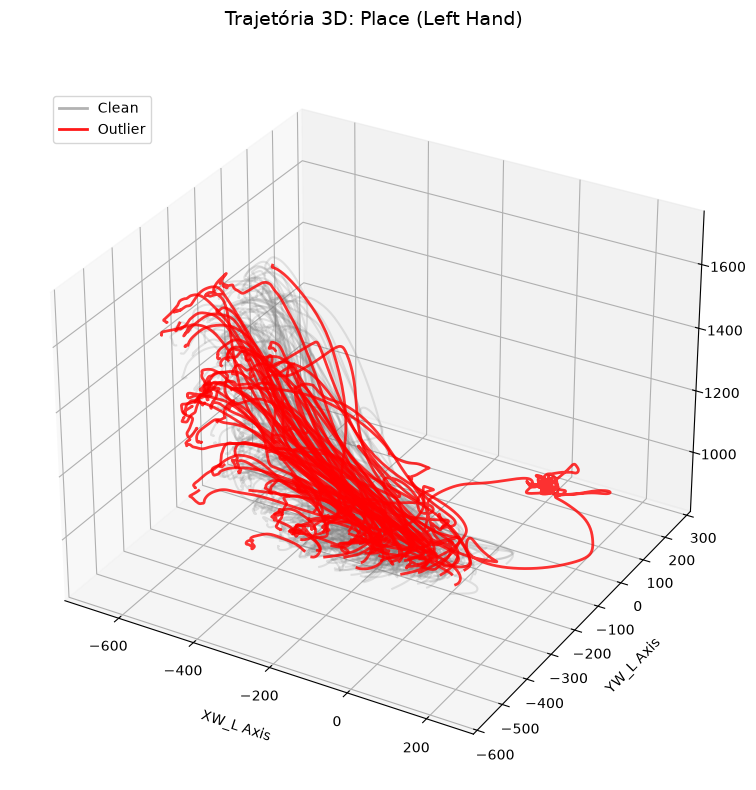

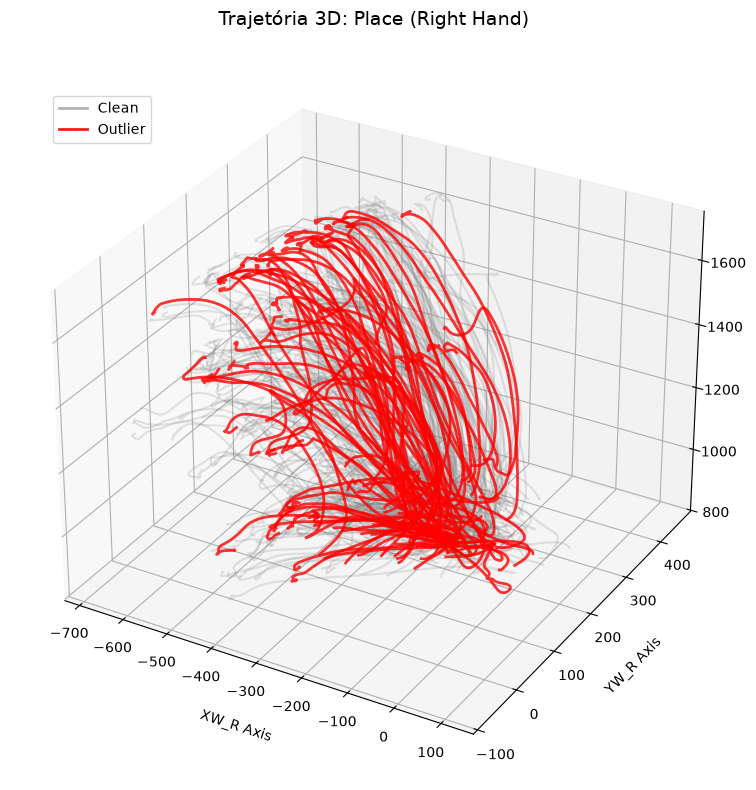

In [6]:
# ==========================================
# DIAGNÓSTICO E VISUALIZAÇÃO DE CONFIGURAÇÃO
# ==========================================

# 1. Escolhe o movimento que queres analisar neste gráfico


TARGET_MOV = 'Place'

# 2. Selecionar o DataFrame de inliers correto com base na tua escolha
if TARGET_MOV == 'Pick':
    inliers_temp = df_inliers_pick.copy()
elif TARGET_MOV == 'Park':
    inliers_temp = df_inliers_park.copy()
elif TARGET_MOV == 'Place':
    inliers_temp = df_inliers_place.copy()
else:
  raise ValueError(f"Invalid TARGET_MOV '{TARGET_MOV}'. Please choose from 'Pick', 'Place', or 'Park'.")

# Criar a chave 'temp_key' para agrupar as séries temporais nos inliers
inliers_temp['temp_key'] = inliers_temp['sub'].astype(str) + "_" + \
                           inliers_temp['repID'].astype(str) + "_" + \
                           inliers_temp['movID'].astype(str)

# 3. EXTRAIR OS OUTLIERS VERDADEIROS
# Vamos ao teu DataFrame original ('df' que carregou o filtered_data.csv completo)
df_original_mov = df[df['movLabel'] == TARGET_MOV].copy()

# Criar a mesma chave 'temp_key' no DataFrame original
df_original_mov['temp_key'] = df_original_mov['sub'].astype(str) + "_" + \
                              df_original_mov['repID'].astype(str) + "_" + \
                              df_original_mov['movID'].astype(str)

# Os outliers detetados são as linhas que estão no original mas NÃO estão nos inliers limpos
outliers_temp = df_original_mov[~df_original_mov['temp_key'].isin(inliers_temp['temp_key'])].copy()

print(f"--- Configuração do Gráfico para {TARGET_MOV} ---")
print(f"Linhas de Inliers (Trajetórias Normais): {len(inliers_temp)}")
print(f"Linhas de Outliers Detetados (Vão aparecer a Vermelho): {len(outliers_temp)}")

print("\n--- A gerar gráfico 3D para a Mão ESQUERDA ---")
plot_movement_data(
    clean_data=inliers_temp,       
    outlier_data=outliers_temp,  
    target_movement=f"{TARGET_MOV} (Left Hand)",
    axis_names=['xw_L', 'yw_L', 'zw_L'] 
)

print("\n--- A gerar gráfico 3D para a Mão DIREITA ---")
plot_movement_data(
    clean_data=inliers_temp,       
    outlier_data=outliers_temp,  
    target_movement=f"{TARGET_MOV} (Right Hand)",
    axis_names=['xw_R', 'yw_R', 'zw_R']
)

plot_movement_data_3d(
    clean_data=inliers_temp,       
    outlier_data=outliers_temp,  
    target_movement=f"{TARGET_MOV} (Left Hand)",
    axis_names=['xw_L', 'yw_L', 'zw_L']
)
plot_movement_data_3d(
    clean_data=inliers_temp,       
    outlier_data=outliers_temp,  
    target_movement=f"{TARGET_MOV} (Right Hand)",
    axis_names=['xw_R', 'yw_R', 'zw_R']
)

In [7]:
# =========================================================================
# PASSO 4: A GRANDE UNIÃO (Identificar os Outliers Globais do Modelo)
# =========================================================================

# 1. Obter as chaves originais de todas as repetições (por movimento)
keys_pick = df[df['movLabel'] == 'Pick'][['sub', 'repID']].drop_duplicates()
keys_move = df[df['movLabel'] == 'Park'][['sub', 'repID']].drop_duplicates()
keys_place = df[df['movLabel'] == 'Place'][['sub', 'repID']].drop_duplicates()

# 2. Obter as chaves dos Inliers que sobreviveram ao teu algoritmo UMAP
# (Usamos um DataFrame vazio de segurança caso o ficheiro falhe)
inliers_pick = df_inliers_pick[['sub', 'repID']].drop_duplicates() if df_inliers_pick is not None else pd.DataFrame(columns=['sub', 'repID'])
inliers_move = df_inliers_park[['sub', 'repID']].drop_duplicates() if df_inliers_park is not None else pd.DataFrame(columns=['sub', 'repID'])
inliers_place = df_inliers_place[['sub', 'repID']].drop_duplicates() if df_inliers_place is not None else pd.DataFrame(columns=['sub', 'repID'])

# 3. Descobrir quem foi detetado como Outlier em cada fase (Anti-Join)
# As anomalias são as repetições que estão nas chaves originais, mas NÃO estão nos inliers!
outliers_pick = pd.merge(keys_pick, inliers_pick, on=['sub', 'repID'], how='left', indicator=True)
outliers_pick = outliers_pick[outliers_pick['_merge'] == 'left_only'].drop(columns=['_merge'])

outliers_move = pd.merge(keys_move, inliers_move, on=['sub', 'repID'], how='left', indicator=True)
outliers_move = outliers_move[outliers_move['_merge'] == 'left_only'].drop(columns=['_merge'])

outliers_place = pd.merge(keys_place, inliers_place, on=['sub', 'repID'], how='left', indicator=True)
outliers_place = outliers_place[outliers_place['_merge'] == 'left_only'].drop(columns=['_merge'])

# 4. A Grande União: Juntar todas as anomalias e remover duplicados
# Se o Sujeito 2 falhou no Pick e no Place da mesma repetição, conta apenas como 1 erro.
outliers_globais_modelo = pd.concat([outliers_pick, outliers_move, outliers_place]).drop_duplicates()

print(f"\n--- RESULTADO DA GRANDE UNIÃO ---")
print(f"Outliers detetados pelo algoritmo no Pick: {len(outliers_pick)}")
print(f"Outliers detetados pelo algoritmo no Park: {len(outliers_move)}")
print(f"Outliers detetados pelo algoritmo no Place: {len(outliers_place)}")
print(f"Total de Repetições na Lista Negra Global: {len(outliers_globais_modelo)}")


--- RESULTADO DA GRANDE UNIÃO ---
Outliers detetados pelo algoritmo no Pick: 0
Outliers detetados pelo algoritmo no Park: 16
Outliers detetados pelo algoritmo no Place: 3
Total de Repetições na Lista Negra Global: 19


In [ ]:
# =========================================================================
# PASSO 5: A GUILHOTINA (Criar o Dataset Ouro)
# =========================================================================
print("\n--- APLICANDO A GUILHOTINA ---")

# Fazer o Anti-Join da Lista Negra Global com o Dataset Bimanual original completo
df_guilhotina = pd.merge(df, outliers_globais_modelo, on=['sub', 'repID'], how='left', indicator=True)

# Manter APENAS as linhas limpas (que não estão na lista negra)
df_gold_standard = df_guilhotina[df_guilhotina['_merge'] == 'left_only'].drop(columns=['_merge'])

print(f"Linhas antes da Guilhotina: {len(df)}")
print(f"Linhas DEPOIS da Guilhotina: {len(df_gold_standard)}")
print(f"✅ Dataset de Ouro (Inliers perfeitos) pronto a usar para ensinar o Robô!")


--- APLICANDO A GUILHOTINA ---
Linhas antes da Guilhotina: 110285
Linhas DEPOIS da Guilhotina: 84751
✅ Dataset de Ouro (Inliers perfeitos) pronto a usar para ensinar o Robô!
Ficheiro de ouro exportado para: ../data/processed/df_final_inliers_gold_standard.csv


Export to csv

In [9]:
import os

# =========================================================================
# PASSO 6: EXPORTAÇÃO INDIVIDUAL (Separar Braços do Dataset de Ouro)
# =========================================================================
print("\n--- A EXPORTAR FICHEIROS DE OURO POR SUJEITO E POR BRAÇO ---")

# Criar a pasta final para os ficheiros separados
output_dir = Configs.SEPARATED_INLIERS_UMAP_DIR
os.makedirs(output_dir, exist_ok=True)

# 1. Definir as colunas base (metadados que são partilhados por ambos os braços)
base_cols = ['sub', 'repID', 'movID', 'movType', 'step', 't']

# 2. Definir as colunas sensoriais que ganharam sufixos (_L e _R)
sensor_and_physics = ['xs', 'ys', 'zs', 'xe', 'ye', 'ze', 'xw', 'yw', 'zw', 'vel', 'acc', 'k']

# 3. A assinatura final exata que pediste (ordem das colunas)
final_signature = [
    'sub', 'repID', 'movID', 'movType', 'step', 
    'xs', 'ys', 'zs', 'xe', 'ye', 'ze', 'xw', 'yw', 'zw', 
    'vel', 'acc', 't', 'k'
]

# ---------------------------------------------------------
# CORREÇÃO: Forçar as colunas de identificação a serem Inteiros!
# ---------------------------------------------------------
colunas_para_inteiro = ['sub', 'repID', 'movID', 'movType', 'step']

for col in colunas_para_inteiro:
    if col in df_gold_standard.columns:
        # O astype(int) corta as casas decimais (ex: 1.0 passa a 1)
        df_gold_standard[col] = df_gold_standard[col].astype(int)
# Vamos iterar sobre cada sujeito que sobreviveu na base de dados limpa
sujeitos_salvos = sorted(df_gold_standard['sub'].unique())

for subject in sujeitos_salvos:
    # Isolar os dados deste sujeito específico
    df_sub = df_gold_standard[df_gold_standard['sub'] == subject].copy()
    
    # ---------------------------------------------------------
    # A. PROCESSAR BRAÇO ESQUERDO
    # ---------------------------------------------------------
    # Criar um dicionário para renomear: {'xs_L': 'xs', 'vel_L': 'vel', ...}
    left_mapping = {f"{col}_L": col for col in sensor_and_physics}
    
    # Selecionar apenas as colunas base e as do braço esquerdo, e renomeá-las
    cols_to_extract_left = base_cols + list(left_mapping.keys())
    
    # Filtrar para não dar erro caso alguma coluna (ex: 'k_L') não exista nalgum dataset
    cols_to_extract_left = [c for c in cols_to_extract_left if c in df_sub.columns]
    left_mapping_safe = {k: v for k, v in left_mapping.items() if k in df_sub.columns}
    
    df_left = df_sub[cols_to_extract_left].rename(columns=left_mapping_safe)
    
    # Ordenar pelas colunas da assinatura final (apenas as que existem)
    final_cols_l = [c for c in final_signature if c in df_left.columns]
    df_left = df_left[final_cols_l]
    
    # Exportar Esquerdo
    left_filename = f"Subject{int(subject)}_left_Tasks.csv"
    df_left.to_csv(os.path.join(output_dir, left_filename), index=False, sep=';')


    # ---------------------------------------------------------
    # B. PROCESSAR BRAÇO DIREITO
    # ---------------------------------------------------------
    # Criar um dicionário para renomear: {'xs_R': 'xs', 'vel_R': 'vel', ...}
    right_mapping = {f"{col}_R": col for col in sensor_and_physics}
    
    # Selecionar apenas as colunas base e as do braço direito, e renomeá-las
    cols_to_extract_right = base_cols + list(right_mapping.keys())
    
    cols_to_extract_right = [c for c in cols_to_extract_right if c in df_sub.columns]
    right_mapping_safe = {k: v for k, v in right_mapping.items() if k in df_sub.columns}
    
    df_right = df_sub[cols_to_extract_right].rename(columns=right_mapping_safe)
    
    # Ordenar pelas colunas da assinatura final (apenas as que existem)
    final_cols_r = [c for c in final_signature if c in df_right.columns]
    df_right = df_right[final_cols_r]
    
    # Exportar Direito
    right_filename = f"Subject{int(subject)}_right_Tasks.csv"
    df_right.to_csv(os.path.join(output_dir, right_filename), index=False, sep=';')

print(f"✅ Exportação Concluída! Foram gerados os ficheiros perfeitos (Left e Right) para {len(sujeitos_salvos)} sujeitos.")
print(f"Podes encontrá-los na pasta: {output_dir}")


--- A EXPORTAR FICHEIROS DE OURO POR SUJEITO E POR BRAÇO ---
✅ Exportação Concluída! Foram gerados os ficheiros perfeitos (Left e Right) para 18 sujeitos.
Podes encontrá-los na pasta: /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/SmartRetail/data/processed/separated_inliers_umap
